## Clustering Customer with K -means

### Step 0: Import the libraries

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ETSU_NAVY ='#00053E'
ETSU_GOLD = '#FFC72C'

print('ready')

ready


### Step 1: Load and explore

In [22]:
df = pd.read_csv("Mall_Customers.csv")
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [23]:
df.shape
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


Step 2: Pick features and scale

In [24]:
features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[features].values
X

scaler = StandardScaler()
Xs = scaler.fit_transform(X) # z_score = (data_point - mean)/std 1,2,3
print("scaled values:",np.round(Xs.mean(axis=0), 3), np.round(Xs.std(axis=0), 3))

scaled values: [-0. -0.] [1. 1.]


In [25]:
Xs

array([[-1.73899919, -0.43480148],
       [-1.73899919,  1.19570407],
       [-1.70082976, -1.71591298],
       [-1.70082976,  1.04041783],
       [-1.66266033, -0.39597992],
       [-1.66266033,  1.00159627],
       [-1.62449091, -1.71591298],
       [-1.62449091,  1.70038436],
       [-1.58632148, -1.83237767],
       [-1.58632148,  0.84631002],
       [-1.58632148, -1.4053405 ],
       [-1.58632148,  1.89449216],
       [-1.54815205, -1.36651894],
       [-1.54815205,  1.04041783],
       [-1.54815205, -1.44416206],
       [-1.54815205,  1.11806095],
       [-1.50998262, -0.59008772],
       [-1.50998262,  0.61338066],
       [-1.43364376, -0.82301709],
       [-1.43364376,  1.8556706 ],
       [-1.39547433, -0.59008772],
       [-1.39547433,  0.88513158],
       [-1.3573049 , -1.75473454],
       [-1.3573049 ,  0.88513158],
       [-1.24279661, -1.4053405 ],
       [-1.24279661,  1.23452563],
       [-1.24279661, -0.7065524 ],
       [-1.24279661,  0.41927286],
       [-1.20462718,

### Step 3: How many clusters?

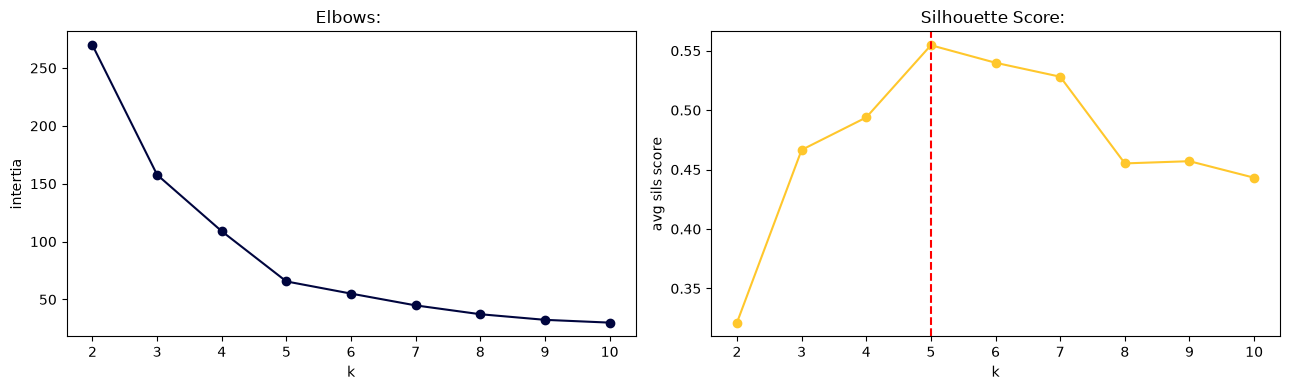

In [26]:
# use intertia and elbow method
# intertia measures how tight the data points are in a cluster
# silhouette score for each point it compares the average distance to points in its own cluster againts 
# the average distance to points the nearest other cluster

ks = range(2, 11)

intertias, sils = [], []

for k in ks:
  km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xs)
  intertias.append(km.inertia_)
  sils.append(silhouette_score(Xs, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(list(ks), intertias, "o-", color=ETSU_NAVY)
ax[0].set_title("Elbows: ");
ax[0].set_xlabel("k"); ax[0].set_ylabel("intertia");

ax[1].plot(list(ks), sils, "o-", color=ETSU_GOLD)
ax[1].set_title("Silhouette Score: ");
ax[1].set_xlabel("k"); ax[1].set_ylabel("avg sils score");

best_k = list(ks)[int(np.argmax(sils))] # [1,3,4,5][3]
ax[1].axvline(best_k, color="red", linestyle="--")
plt.tight_layout();
plt.show();

### Step 5: Fit k-means with the optimal k


In [27]:
k = 5
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xs) # run this algo k mean to create teh clusters
df["cluster"] = kmeans.labels_ # attach the customer id with the clusters
df[["Annual Income (k$)", "Spending Score (1-100)", "cluster"]].head()

,Annual Income (k$),Spending Score (1-100),cluster
0,15,39,4
1,15,81,2
2,16,6,4
3,16,77,2
4,17,40,4


### Step 6: Visualize the clusters

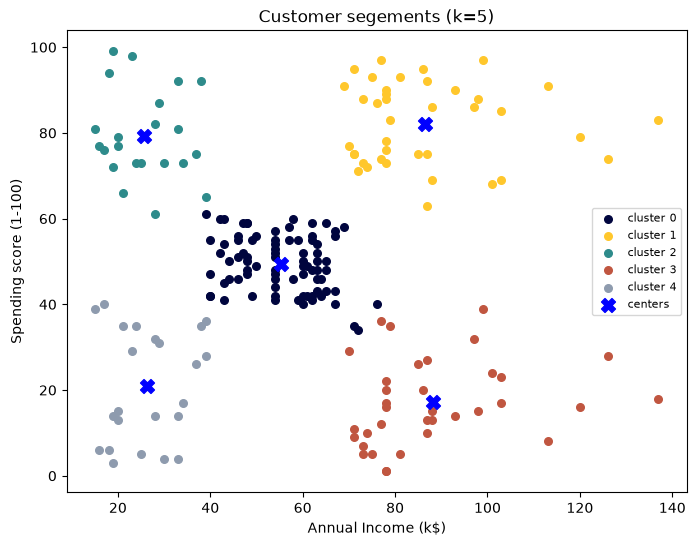

In [28]:
PALETTE = ["#00053E", "#FFC72C", "#2E8B8B", "#C05640", "#8E9BAE"]  # up to 5 clusters

plt.figure(figsize=(8, 6))
for c in range(k):
  m = df["cluster"] == c
  plt.scatter(df.loc[m, "Annual Income (k$)"], df.loc[m, "Spending Score (1-100)"], s=30, color=PALETTE[c], label=f"cluster {c}")

# change center clusters back in original units
centers = df.groupby("cluster")[features].mean()

plt.scatter(centers[features[0]], centers[features[1]], s=100, marker="X", color="blue", label="centers")

plt.xlabel("Annual Income (k$)");
plt.ylabel("Spending score (1-100)");
plt.title("Customer segements (k=5)");
plt.legend(fontsize=8);
plt.show()


### Step 7: Profiling cluster segments

In [29]:
profile = df.groupby("cluster").agg(
    customers=("CustomerID", "count"),
    avg_income=("Annual Income (k$)", "mean"),
    avg_spending=("Spending Score (1-100)", "mean"),
).round(1)
profile

,customers,avg_income,avg_spending
cluster,,,
0,81,55.3,49.5
1,39,86.5,82.1
2,22,25.7,79.4
3,35,88.2,17.1
4,23,26.3,20.9


In [30]:
df

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4
...,...,...,...,...,...,...
195,196,Female,35,120,79,1
196,197,Female,45,126,28,3
197,198,Male,32,126,74,1
198,199,Male,32,137,18,3


In [ ]:
# --- Name the segments and export for Power BI ---

inc, spd = "Annual Income (k$)", "Spending Score (1-100)"   # short handles for the two columns we judge on
inc_med, spd_med = df[inc].median(), df[spd].median()        # the middle income and spending, used as the high/low line

# name each cluster from its OWN average income and spending, so it works
# no matter how k-means numbered the clusters this run


def name_cluster(c):
    g = df[df["cluster"] == c]  # just the customers in cluster c
    
    hi_inc, lo_inc = g[inc].mean() > inc_med + 12, g[inc].mean() < inc_med - 12   # is this cluster's avg income clearly above / below the middle?
    hi_spd, lo_spd = g[spd].mean() > spd_med + 12, g[spd].mean() < spd_med - 12   # same check for spending (12 = a buffer so mid groups aren't forced into a corner)
    
    # pick the name by which corner the cluster sits in; anything not clearly in a corner is the middle group
    
    if hi_inc and hi_spd: return "Target (high income, high spend)"
    if hi_inc and lo_spd: return "Careful (high income, low spend)"
    if lo_inc and hi_spd: return "Young Spenders (low income, high spend)"
    if lo_inc and lo_spd: return "Budget (low income, low spend)"
    
    return "Standard (mid income, mid spend)"


# build a {cluster number: name} lookup for the clusters present, then label every row with its segment
df["Segment"] = df["cluster"].map({c: name_cluster(c) for c in df["cluster"].unique()})


In [ ]:
# write the file Power BI will load (drop the raw cluster number so only the readable Segment remains)

df.drop(columns=["cluster"]).to_csv("mall_customers_segments.csv", index=False)
print("Saved mall_customers_segments.csv")
df.head() # Yayyy, now we have a Segment column -- boom !

Saved mall_customers_segments.csv


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),cluster,Segment
0,1,Male,19,15,39,4,"Budget (low income, low spend)"
1,2,Male,21,15,81,2,"Young Spenders (low income, high spend)"
2,3,Female,20,16,6,4,"Budget (low income, low spend)"
3,4,Female,23,16,77,2,"Young Spenders (low income, high spend)"
4,5,Female,31,17,40,4,"Budget (low income, low spend)"
